# Feature ablation: which features can be dropped?

`feature_analysis.ipynb` flagged redundant / weak features by correlation, but correlation does not prove a feature
is useless. Here each feature (or group) is **removed and the model retrained**; if test error does not get worse,
the feature is safe to drop.

- **Models**: gradient boosting (HistGBR, native categoricals, insensitive to redundancy) and ridge regression
  (one-hot + standardized numerics, same prep as `engines/ridge_regression`, sensitive to collinearity / noise).
- **Target**: log price. **Metric**: test RMSE (log) and MdAPE.
- **Splits**: every seed in the config (`load_splits`, stratified by property type); train on train+val, score on
  test. Δ is paired per seed (drop-run minus baseline-run on the same split), reported as mean ± standard error.
- `*_missing` flags are dropped together with their base feature.

Data: `data/clean/data_filtered.csv`. Features: the lists in `configs/neural_network_config.yml`.

In [1]:
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

LAB = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "engines" / "common.py").exists())
sys.path.insert(0, str(LAB))
from engines.common import load_config, load_splits

DATA = "data/clean/data_filtered.csv"

pd.set_option("display.width", 200)
BLUE, RED, GRAY, INK, INK2 = "#257de0", "#ec4647", "#d9d9d9", "#191919", "#666666"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": "#eeeeee", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
})

cfg = load_config()
FC, dc = cfg["features"], cfg["data"]
TARGET = dc["target"]
CAT, NUM, BIN = FC["categorical"], FC["numeric"], FC["binary"]
LOG = FC.get("log", [])
SEEDS = dc.get("seeds") or [dc["seed"]]
ALL = CAT + NUM + BIN
print(f"{DATA} | seeds {SEEDS} | {len(ALL)} features")

data/clean/data_filtered.csv | seeds [42, 7, 13, 21, 99] | 24 features


## Experiments

In [2]:
MISSING = {"area_m2": ["area_m2_missing"], "bedrooms": ["bedrooms_missing"], "bathrooms": ["bathrooms_missing"],
           "floor_level": ["floor_level_missing"], "land_width_m": ["land_dims_missing"],
           "land_length_m": ["land_dims_missing"]}
AMENITIES = ["in_borey", "has_gym", "has_lift", "has_parking", "has_pool", "has_sauna", "on_main_road"]


def with_flags(cols):
    out = []
    for c in cols:
        out += [c, *MISSING.get(c, [])]
    return sorted(set(out), key=ALL.index)


EXPERIMENTS = {"baseline (all features)": []}
for c in CAT + NUM + AMENITIES:
    EXPERIMENTS[f"- {c}"] = with_flags([c])
EXPERIMENTS |= {
    "- bedrooms + bathrooms": with_flags(["bedrooms", "bathrooms"]),
    "- land width + length": with_flags(["land_width_m", "land_length_m"]),
    "- all amenity flags": AMENITIES,
    "- all *_missing flags": [c for c in BIN if c.endswith("_missing")],
    "- proposed set": with_flags(["bathrooms", "province", "land_width_m", "land_length_m", "title_deed"]),
}
for name, drop in EXPERIMENTS.items():
    assert set(drop) <= set(ALL), (name, drop)
print(f"{len(EXPERIMENTS)} experiments x {len(SEEDS)} seeds x 2 models")
print("proposed set drops:", EXPERIMENTS["- proposed set"])

25 experiments x 5 seeds x 2 models
proposed set drops: ['province', 'title_deed', 'land_width_m', 'land_length_m', 'bathrooms', 'bathrooms_missing', 'land_dims_missing']


## Models

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def prep(df):
    """Cleaned categoricals (commune keyed by district), log1p size numerics, 0/1 flags."""
    x = pd.DataFrame(index=df.index)
    for c in CAT:
        x[c] = df[c].astype("string").fillna("Unknown").str.strip()
    x["commune"] = x["district"] + "|" + x["commune"]  # commune names repeat across districts
    for c in NUM:
        v = df[c].astype(float).clip(lower=0)
        x[c] = np.log1p(v) if c in LOG else v
    for c in BIN:
        x[c] = df[c].astype(float)
    return x


def fit_gb(xtr, ytr, xte, feats):
    cats = [c for c in feats if c in CAT]
    a, b = xtr[feats].copy(), xte[feats].copy()
    for c in cats:
        levels = pd.Index(sorted(a[c].unique()))
        a[c] = levels.get_indexer(a[c]).astype(float)
        b[c] = levels.get_indexer(b[c]).astype(float)
        b.loc[b[c] < 0, c] = np.nan  # unseen in train
    gb = HistGradientBoostingRegressor(categorical_features=[feats.index(c) for c in cats] or None,
                                       max_iter=400, learning_rate=0.06, random_state=0)
    return gb.fit(a, ytr).predict(b)


def fit_ridge(xtr, ytr, xte, feats):
    parts = []
    if cats := [c for c in feats if c in CAT]:
        parts.append(("cat", OneHotEncoder(min_frequency=FC["min_count"], handle_unknown="infrequent_if_exist"), cats))
    if nums := [c for c in feats if c in NUM]:
        parts.append(("num", StandardScaler(), nums))
    if bins := [c for c in feats if c in BIN]:
        parts.append(("bin", "passthrough", bins))
    pipe = make_pipeline(ColumnTransformer(parts), RidgeCV(alphas=np.logspace(-2, 3, 11)))
    return pipe.fit(xtr[feats], ytr).predict(xte[feats])


MODELS = {"gradient boosting": fit_gb, "ridge": fit_ridge}

## Run

In [4]:
splits = {}
for s in SEEDS:
    tr, va, te = load_splits(DATA, dc["test_size"], dc["val_size"], s)
    tr = pd.concat([tr, va], ignore_index=True)
    splits[s] = prep(tr), np.log(tr[TARGET].to_numpy()), prep(te), te[TARGET].to_numpy()

rows, t0 = [], time.time()
for name, drop in EXPERIMENTS.items():
    feats = [c for c in ALL if c not in drop]
    for model, fit in MODELS.items():
        for s, (xtr, ytr, xte, price) in splits.items():
            pred = fit(xtr, ytr, xte, feats)
            rows.append(dict(experiment=name, model=model, seed=s,
                             rmse=np.sqrt(np.mean((pred - np.log(price)) ** 2)),
                             mdape=np.median(np.abs(np.exp(pred) - price) / price) * 100))
print(f"{len(rows)} fits in {time.time() - t0:.0f}s")
res = pd.DataFrame(rows)

250 fits in 255s


## Results

Δ = (error without the feature) − (error with all features), same split. **Positive Δ = the model got worse =
the feature carries signal.** Verdict uses the paired standard error across seeds:

- **keep**: Δ RMSE > 2·SE (removing it reliably hurts)
- **drop helps**: Δ RMSE < −2·SE (the model is better without it)
- **no effect**: within noise, safe to drop

In [5]:
base = res[res.experiment == "baseline (all features)"].set_index(["model", "seed"])[["rmse", "mdape"]]
delta = res.join(base, on=["model", "seed"], rsuffix="_base")
delta["d_rmse"] = delta.rmse - delta.rmse_base
delta["d_mdape"] = delta.mdape - delta.mdape_base
delta = delta[delta.experiment != "baseline (all features)"]

n = len(SEEDS)
summ = (delta.groupby(["experiment", "model"], sort=False)
        .agg(d_rmse=("d_rmse", "mean"), se=("d_rmse", lambda v: v.std(ddof=1) / np.sqrt(n)),
             d_mdape=("d_mdape", "mean"), worse_seeds=("d_rmse", lambda v: int((v > 0).sum())))
        .reset_index())
summ["verdict"] = np.select([summ.d_rmse > 2 * summ.se, summ.d_rmse < -2 * summ.se],
                            ["keep", "drop helps"], "no effect")

print("baseline (all features), mean over seeds:")
display(base.groupby("model").mean().round(4))

wide = summ.pivot(index="experiment", columns="model", values=["d_rmse", "se", "d_mdape", "verdict"])
wide = wide.reindex(summ.experiment.unique())
wide.columns = [f"{m} | {v}" for v, m in wide.columns]
wide = wide[[f"{m} | {v}" for m in MODELS for v in ["d_rmse", "se", "d_mdape", "verdict"]]]
display(wide.style.format({c: "{:+.4f}" for c in wide.columns if c.endswith(("d_rmse", "se"))}
                          | {c: "{:+.2f}" for c in wide.columns if c.endswith("d_mdape")}))

baseline (all features), mean over seeds:


,rmse,mdape
model,,
gradient boosting,0.4275,22.3942
ridge,0.4870,26.9204


,gradient boosting | d_rmse,gradient boosting | se,gradient boosting | d_mdape,gradient boosting | verdict,ridge | d_rmse,ridge | se,ridge | d_mdape,ridge | verdict
experiment,,,,,,,,
- property_type,+0.0070,+0.0018,+0.66,keep,+0.0162,+0.0013,+0.91,keep
- province,-0.0003,+0.0007,+0.26,no effect,+0.0002,+0.0005,+0.13,no effect
- district,+0.0025,+0.0019,+0.32,no effect,+0.0026,+0.0004,+0.07,keep
- commune,+0.0046,+0.0018,+0.72,keep,+0.0140,+0.0009,+1.69,keep
- borey_name,+0.0010,+0.0015,+0.12,no effect,+0.0024,+0.0004,+0.49,keep
- title_deed,+0.0043,+0.0010,+0.16,keep,+0.0025,+0.0002,-0.08,keep
- area_m2,+0.0549,+0.0049,+2.32,keep,+0.1043,+0.0079,+5.50,keep
- land_width_m,+0.0031,+0.0009,+0.04,keep,-0.0003,+0.0005,-0.14,no effect
- land_length_m,+0.0004,+0.0013,+0.20,no effect,+0.0002,+0.0001,-0.07,no effect


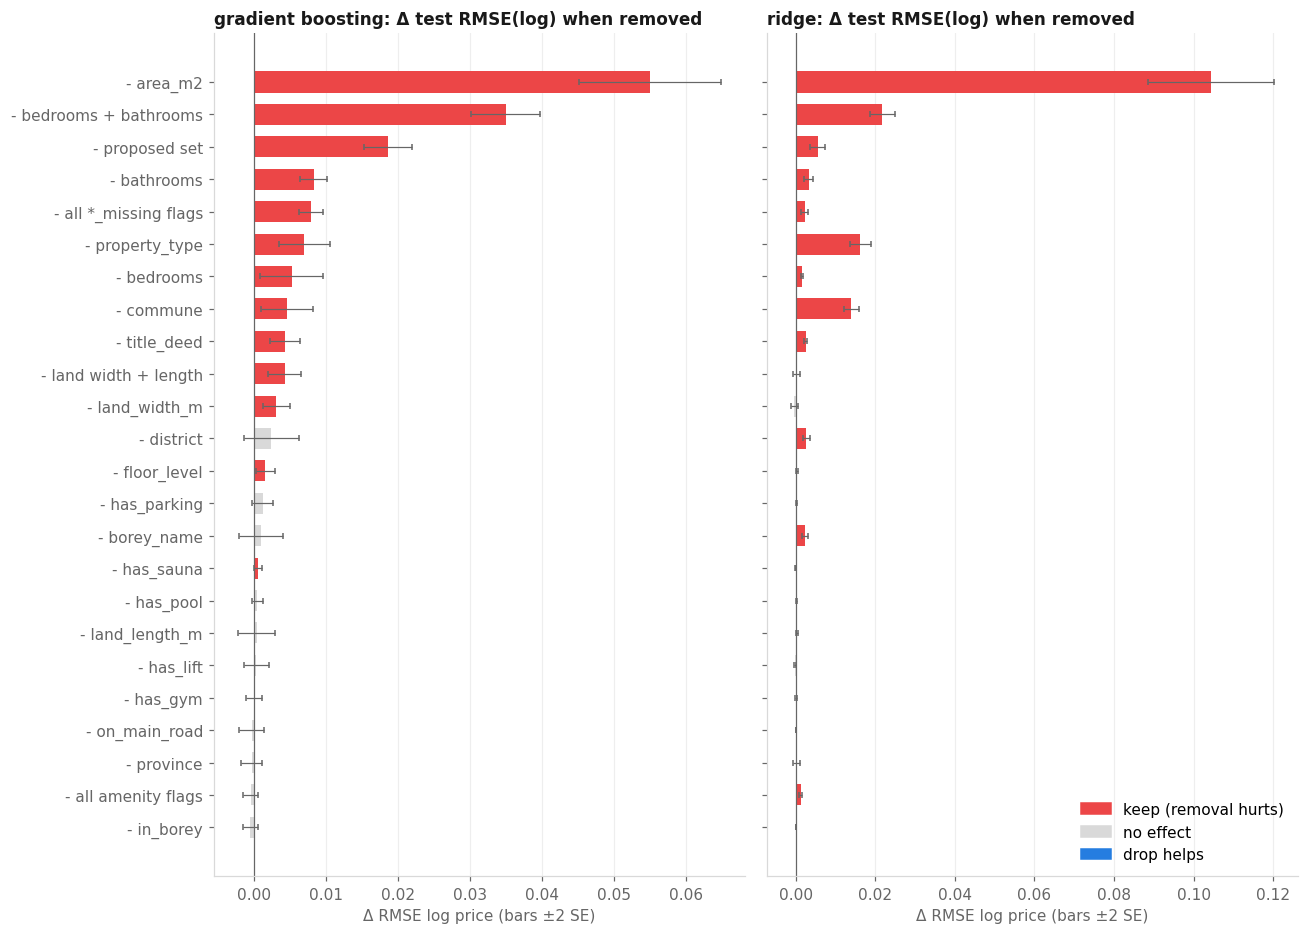

In [6]:
order = summ[summ.model == "gradient boosting"].sort_values("d_rmse").experiment.tolist()
fig, axes = plt.subplots(1, 2, figsize=(12, 0.3 * len(order) + 1.4), sharey=True)
for ax, model in zip(axes, MODELS):
    s = summ[summ.model == model].set_index("experiment").loc[order]
    colors = np.where(s.verdict == "keep", RED, np.where(s.verdict == "drop helps", BLUE, GRAY))
    ax.barh(s.index, s.d_rmse, xerr=2 * s.se, color=colors, height=0.65,
            error_kw=dict(ecolor=INK2, lw=0.8, capsize=2))
    ax.axvline(0, color=INK2, lw=0.8)
    ax.grid(axis="y", visible=False)
    ax.set(title=f"{model}: Δ test RMSE(log) when removed", xlabel="Δ RMSE log price (bars ±2 SE)")
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color=RED, label="keep (removal hurts)"), Patch(color=GRAY, label="no effect"),
                        Patch(color=BLUE, label="drop helps")], loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

## Verdict

In [7]:
v = summ.pivot(index="experiment", columns="model", values="verdict").reindex(order[::-1])
safe = v[(v != "keep").all(axis=1)].index.tolist()
must = v[(v == "keep").all(axis=1)].index.tolist()
print("safe to drop (no model hurt):")
for e in safe:
    print(f"  {e:28s} gb: {v.loc[e, 'gradient boosting']:10s} ridge: {v.loc[e, 'ridge']}")
print("\nkeep (both models hurt):", ", ".join(e.removeprefix("- ") for e in must))
mixed = [e for e in v.index if e not in safe and e not in must]
print("mixed (hurts one model only):", ", ".join(e.removeprefix("- ") for e in mixed) or "none")

safe to drop (no model hurt):
  - has_parking                gb: no effect  ridge: no effect
  - has_pool                   gb: no effect  ridge: no effect
  - land_length_m              gb: no effect  ridge: no effect
  - has_lift                   gb: no effect  ridge: no effect
  - has_gym                    gb: no effect  ridge: no effect
  - on_main_road               gb: no effect  ridge: no effect
  - province                   gb: no effect  ridge: no effect
  - in_borey                   gb: no effect  ridge: no effect

keep (both models hurt): area_m2, bedrooms + bathrooms, proposed set, bathrooms, all *_missing flags, property_type, bedrooms, commune, title_deed
mixed (hurts one model only): land width + length, land_width_m, district, floor_level, borey_name, has_sauna, all amenity flags
